In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
df=pd.read_csv('train.csv')

In [ ]:
display(df.head(5))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
rows,columns=df.shape
print('Rows',rows)
print('columns',columns)

Rows 891
columns 12


## Audit data types and missing values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
display(df.dtypes)

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
missing_values=df.isna().sum()
missing_percentage=((missing_values/len(df))*100).round(2)
report_missing_values=pd.DataFrame({'Missing Values':missing_values,'Missing Percentage':missing_percentage})
display(report_missing_values.sort_values(by='Missing Values',ascending=False))

,Missing Values,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


## Numeric part


In [ ]:
descriptive=df.describe(include='number').T
display(descriptive)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


## Duplicated

In [ ]:
duplicated_value=df.duplicated()
duplicated_value.sum()

np.int64(0)

In [ ]:
all_full_duplicates = df[df.duplicated(keep=False)]

In [ ]:
all_full_duplicates

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [ ]:
df['PassengerId'].duplicated().sum()

np.int64(0)

In [ ]:
print("\nAge Statistics:")
print(df['Age'].describe())
print(f"Missing Age values: {df['Age'].isnull().sum()}")

print("\nFare Statistics:")
print(df['Fare'].describe())


Age Statistics:
count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64
Missing Age values: 177

Fare Statistics:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


## Count each Survived class and investigate possible invalid values.


In [ ]:
total_value=df.Survived.value_counts()
percentage=df.Survived.value_counts(normalize=True).round(2)
report_survived=pd.DataFrame({'Total':total_value,'Percentage':percentage})
display(report_survived)


,Total,Percentage
Survived,,
0,549,0.62
1,342,0.38


In [ ]:
df.Age.min()
df.Age.max()

80.0

In [ ]:
numeric_columns = df.select_dtypes(include='number').columns
for i in numeric_columns:
  print(i)
  print(df[i].describe())

PassengerId
count    891.000000
mean     446.000000
std      257.353842
min        1.000000
25%      223.500000
50%      446.000000
75%      668.500000
max      891.000000
Name: PassengerId, dtype: float64
Survived
count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64
Pclass
count    891.000000
mean       2.308642
std        0.836071
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        3.000000
Name: Pclass, dtype: float64
Age
count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64
SibSp
count    891.000000
mean       0.523008
std        1.102743
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        8.000000
Name: SibSp, dtype: float64
Parch
count   

### Cleaning log — fill in after inspecting the data

| Issue found | Columns affected | Decision | Why? |
|---|---|---|---|
| Minimum age is 0.42 | Age | Convert it into flag|Keep as it as|
|Missing values | Cabin | Drop/Exclude from the Baseline | More numbers are Missing value |
|Missing Values | Age/Embarked | Median / Mode |Removes the Null value |
|Drop Columns | PassengerID, Name Ticket , Cabin | Because It is not useful for model building  |  So we can drop these columns|
|Not categorical  | PClass | It is a Numeric column but actually it is a categorical columns  | So we will change  |


**Important:** Keep learned imputation/statistical transformations inside training pipelines after the train/test split.

## EDA

<Axes: xlabel='Pclass'>

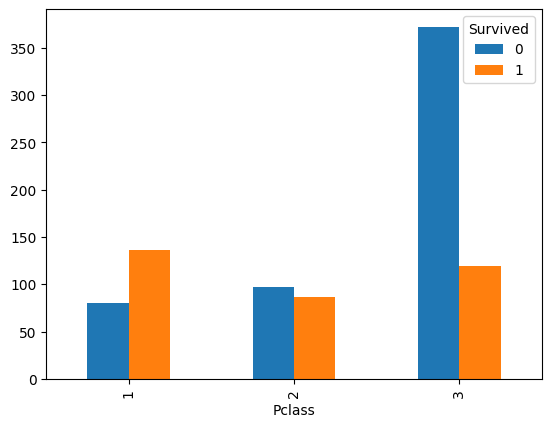

In [ ]:

df.groupby('Pclass')['Survived'].value_counts().unstack().plot(kind='bar')

<Axes: xlabel='Sex,Survived'>

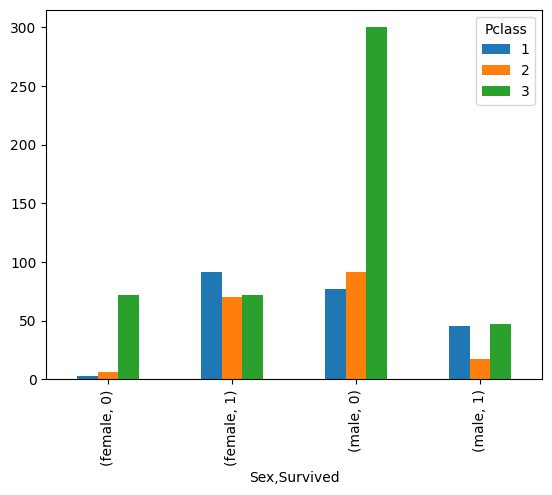

In [ ]:
df.groupby('Sex')[['Survived','Pclass']].value_counts().unstack().plot(kind='bar')

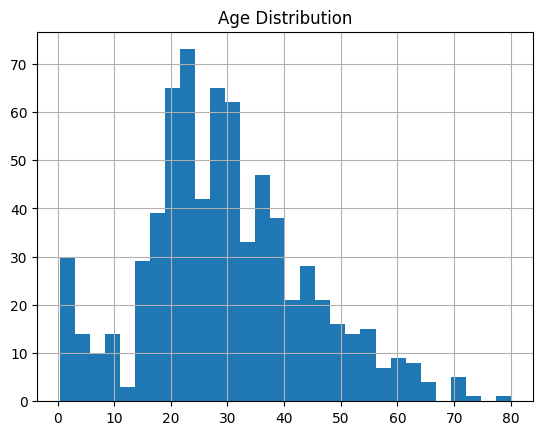

In [ ]:
df['Age'].hist(bins=30)
plt.title('Age Distribution')
plt.show()

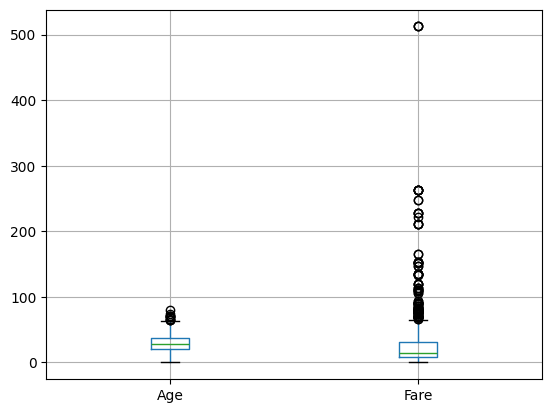

In [ ]:
df.boxplot(column=['Age', 'Fare'])
plt.show()

<Axes: >

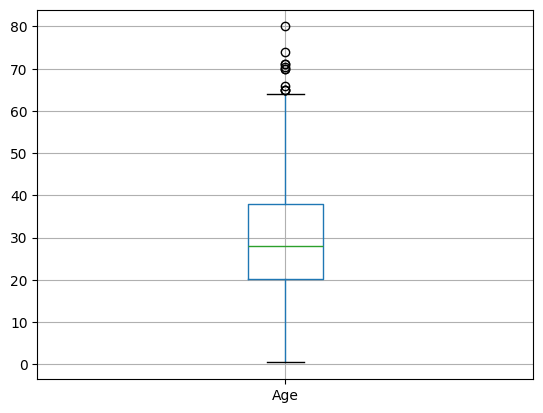

In [ ]:
df.boxplot(column=['Age'])

/tmp/ipykernel_648/2857165431.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x='Age', hue='Survived', shade=True)


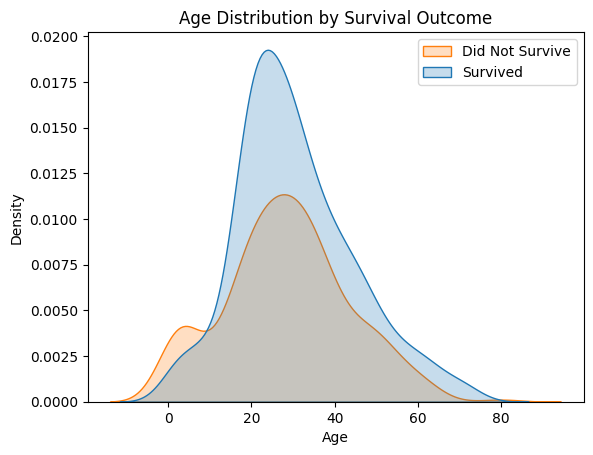

In [ ]:
sns.kdeplot(data=df, x='Age', hue='Survived', shade=True)
plt.title("Age Distribution by Survival Outcome")
plt.xlabel("Age")
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

/tmp/ipykernel_648/1119808827.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x='Fare', hue='Survived', shade=True)


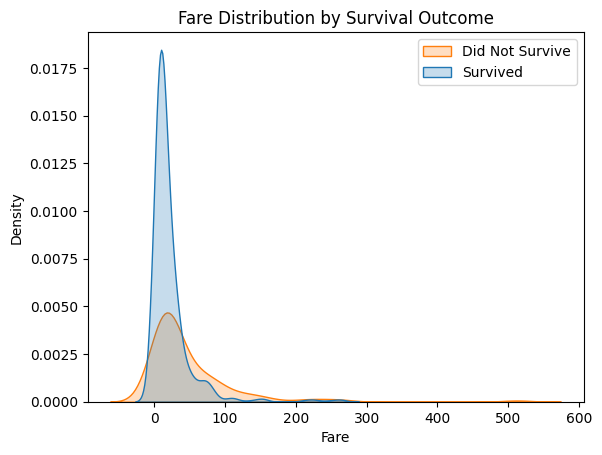

In [ ]:
sns.kdeplot(data=df, x='Fare', hue='Survived', shade=True)
plt.title("Fare Distribution by Survival Outcome")
plt.xlabel("Fare")
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

### EDA observations

1. Observation 1: With observation1 we can say that most people who died were from 3rd class
2. Observation 2: Male have highest number of died
3. Observation 3: Those people which gave highest amount of money they are mostly survived and most people who died in it were from 10 to 50 age group

## Clean data

In [ ]:
clean=df.copy()


In [ ]:
clean=clean.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
clean.shape

(891, 8)

In [ ]:
# # Fill null values
# clean['Age']=clean.Age.fillna(clean.Age.median())
# clean['Embarked']=clean.Embarked.fillna(clean.Embarked.mode()[0])

In [ ]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [ ]:
# Convert into a categorical columns
clean['Pclass'] = clean['Pclass'].astype('category')

In [ ]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Survived  891 non-null    int64   
 1   Pclass    891 non-null    category
 2   Sex       891 non-null    object  
 3   Age       714 non-null    float64 
 4   SibSp     891 non-null    int64   
 5   Parch     891 non-null    int64   
 6   Fare      891 non-null    float64 
 7   Embarked  889 non-null    object  
dtypes: category(1), float64(2), int64(3), object(2)
memory usage: 49.9+ KB


## Split the Datasets

In [ ]:
X=clean.drop('Survived',axis=1)
y=clean.Survived

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 7)
(179, 7)
(712,)
(179,)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
numeric_pipline=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])
categorical_pipline=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

In [ ]:
preprocessor=ColumnTransformer(transformers=[
    ('num',numeric_pipline,['Age','Fare']),
    ('cat',categorical_pipline,['Pclass','Sex','Embarked'])
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Pclass', 'Sex', 'Embarked'])])

### Explain data leakage (2–3 sentences)

**Your answer:** Data leakage means model seen the unseen data or test data which means it may do overfitting and donot give good accuracy on unseen data

In [ ]:
from sklearn.linear_model import LogisticRegression
model1=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',LogisticRegression(max_iter=100,random_state=42))
])
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
print(classification_report(y_test,y_pred))
accuracy_score(y_test,y_pred)

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



0.770949720670391

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model2=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',KNeighborsClassifier(n_neighbors=5))
])
model2.fit(X_train,y_train)
y_pred2=model2.predict(X_test)

In [ ]:
print(classification_report(y_test,y_pred2))
print('Accuracy',accuracy_score(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87       110
           1       0.83      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179

Accuracy 0.8268156424581006


In [ ]:
from sklearn.tree import DecisionTreeClassifier
model3=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',DecisionTreeClassifier())
])
model3.fit(X_train,y_train)
y_pred3=model3.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred3)
print(f"Accuracy: {accuracy}")

Accuracy: 0.7932960893854749


In [ ]:
from sklearn.ensemble import RandomForestClassifier
model4=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',RandomForestClassifier())
])
model4.fit(X_train,y_train)
y_pred4=model4.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred4)
print(f"Accuracy: {accuracy}")

Accuracy: 0.8156424581005587


In [ ]:
models = {
    'Logistic Regression': model1,
    'KNN': model2,
    'Decision Tree': model3,
    'Random Forest': model4
}
for name, model in models.items():
    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)

    print(f"{name}: {score:.4f}")

Logistic Regression: 0.7709
KNN: 0.8268
Decision Tree: 0.8101
Random Forest: 0.8380


## Cross validation comparision

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [ ]:
results = []

for name, model in models.items():

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Precision Mean': scores['test_precision'].mean(),
        'Recall Mean': scores['test_recall'].mean(),
        'F1 Mean': scores['test_f1'].mean(),
        'F1 Std': scores['test_f1'].std(),
        'ROC-AUC Mean': scores['test_roc_auc'].mean()
    })
cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by='F1 Mean',
    ascending=False
)

cv_results

,Model,Accuracy Mean,Precision Mean,Recall Mean,F1 Mean,F1 Std,ROC-AUC Mean
3,Random Forest,0.801960,0.753786,0.721616,0.736565,0.019791,0.862312
1,KNN,0.800571,0.771885,0.692189,0.727160,0.027151,0.852791
0,Logistic Regression,0.793578,0.750120,0.696162,0.720836,0.023814,0.853309
2,Decision Tree,0.783719,0.728663,0.703704,0.713339,0.019917,0.764369


## Grid search CV

In [ ]:
params_logistic = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']
}
params_knn={
    'classifier__n_neighbors':[3,5,7],
    'classifier__weights':['uniform','distance'],
}
params_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [None, 3, 5, 10],
    'classifier__min_samples_split': [2, 5, 10]
}

params_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_leaf': [1, 3]
}



In [ ]:
from sklearn.model_selection import GridSearchCV
grid_search_logistic=GridSearchCV(
    estimator=model1,
    param_grid=params_logistic,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search_logistic.fit(X_train,y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'Embarked'])])),
                                       ('classifier',
                                        LogisticRegression(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.01, 0.1, 1, 10],
                         'classifier__penalty': ['l1', 'l2'],
                         'classifier__solver': ['liblinear']},
             scoring='f1')

In [ ]:
print("Best Parameters:", grid_search_logistic.best_params_)
print("Best F1 Score:", grid_search_logistic.best_score_)

Best Parameters: {'classifier__C': 1, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best F1 Score: 0.724401487799972


In [ ]:
grid_search_knn = GridSearchCV(
    estimator=model2,
    param_grid=params_knn,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search_knn.fit(X_train, y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'Embarked'])])),
                                       ('classifier', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__n_neighbors': [3, 5, 7],
                         'classifier__weights': ['uniform', 'distance']},
             scoring='f1')

In [ ]:
print("Best Parameters:", grid_search_knn.best_params_)
print("Best F1 Score:", grid_search_knn.best_score_)

Best Parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}
Best F1 Score: 0.744826866661729


In [ ]:
grid_search_decision_tree = GridSearchCV(
    estimator=model3,
    param_grid=params_dt,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search_decision_tree.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'Embarked'])])),
                                       ('classifier',
                                        DecisionTreeClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__criterion': ['gini', 'entropy'],
                         'classifier__max_depth': [None, 3, 5, 10],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='f1')

In [ ]:
print("Best Parameters:", grid_search_decision_tree.best_params_)
print("Best F1 Score:", grid_search_decision_tree.best_score_)

Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 10}
Best F1 Score: 0.7452597870852817


In [ ]:
grid_search_randomforest= GridSearchCV(
    estimator=model4,
    param_grid=params_rf,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search_randomforest.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'Embarked'])])),
                                       ('classifier',
                                        RandomForestClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [None, 5, 10],
                         'classifier__min_samples_leaf': [1, 3],
                         'classifier__n_estimators': [100, 200]},
             scoring='f1')

In [ ]:
print('Best parameters',grid_search_randomforest.best_params_)
print('Best F1 Score',grid_search_randomforest.best_score_)

Best parameters {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
Best F1 Score 0.7515827383585012


In [ ]:
# Baseline CV results
baseline_comparison = cv_results[
    ['Model', 'F1 Mean', 'F1 Std']
].copy()

baseline_comparison['Type'] = 'Baseline'
baseline_comparison = baseline_comparison.rename(
    columns={
        'Model': 'Candidate',
        'F1 Mean': 'CV F1 Mean',
        'F1 Std': 'CV F1 Std'
    }
)

# Tuned model results
tuned_searches = {
    'Tuned Logistic Regression': grid_search_logistic,
    'Tuned KNN': grid_search_knn,
    'Tuned Decision Tree': grid_search_decision_tree,
    'Tuned Random Forest': grid_search_randomforest
}

tuned_results = []

for name, search in tuned_searches.items():
    tuned_results.append({
        'Candidate': name,
        'CV F1 Mean': search.best_score_,
        'CV F1 Std': search.cv_results_['std_test_score'][
            search.best_index_
        ],
        'Type': 'Tuned'
    })

tuned_comparison = pd.DataFrame(tuned_results)

# Combine both comparisons
final_comparison = pd.concat(
    [baseline_comparison, tuned_comparison],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    'CV F1 Mean',
    ascending=False
).reset_index(drop=True)

display(final_comparison)

,Candidate,CV F1 Mean,CV F1 Std,Type
0,Tuned Random Forest,0.751583,0.054486,Tuned
1,Tuned Decision Tree,0.745260,0.074260,Tuned
2,Tuned KNN,0.744827,0.029363,Tuned
3,Random Forest,0.736565,0.019791,Baseline
4,KNN,0.727160,0.027151,Baseline
5,Tuned Logistic Regression,0.724401,0.049337,Tuned
6,Logistic Regression,0.720836,0.023814,Baseline
7,Decision Tree,0.713339,0.019917,Baseline


In [ ]:
baseline_comparison = cv_results[
    ['Model', 'F1 Mean', 'F1 Std']
].copy()

baseline_comparison['Type']='Baseline'
baseline_comparison = baseline_comparison.rename(
    columns={
        'Model': 'Candidate',
        'F1 Mean': 'CV F1 Mean',
        'F1 Std': 'CV F1 Std'
    }
)
baseline_comparison

,Candidate,CV F1 Mean,CV F1 Std,Type
3,Random Forest,0.736565,0.019791,Baseline
1,KNN,0.727160,0.027151,Baseline
0,Logistic Regression,0.720836,0.023814,Baseline
2,Decision Tree,0.713339,0.019917,Baseline


In [ ]:
tuned_searches = {
    'Tuned Logistic Regression': grid_search_logistic,
    'Tuned KNN': grid_search_knn,
    'Tuned Decision Tree': grid_search_decision_tree,
    'Tuned Random Forest': grid_search_randomforest
}
tuned_result=[]
for name,search in tuned_searches.items():
    tuned_result.append({
        'Model':name,
        'CV F1 Mean':search.best_score_,
        'CV F1 Std':search.cv_results_['std_test_score'][search.best_index_],
        'Type':'Tuned'
    })
tuned_comparison = pd.DataFrame(tuned_results)

In [ ]:
comparision=pd.concat([baseline_comparison,tuned_comparison],ignore_index=True)
display(comparision.sort_values('CV F1 Mean',ascending=False).reset_index(drop=True))

,Candidate,CV F1 Mean,CV F1 Std,Type
0,Tuned Random Forest,0.751583,0.054486,Tuned
1,Tuned Decision Tree,0.745260,0.074260,Tuned
2,Tuned KNN,0.744827,0.029363,Tuned
3,Random Forest,0.736565,0.019791,Baseline
4,KNN,0.727160,0.027151,Baseline
5,Tuned Logistic Regression,0.724401,0.049337,Tuned
6,Logistic Regression,0.720836,0.023814,Baseline
7,Decision Tree,0.713339,0.019917,Baseline


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# Collect all candidates
candidates = {
    **models,
    **tuned_searches
}

# Select the candidate with the highest mean CV F1
best_name = final_comparison.iloc[0]['Candidate']

final_model = candidates[best_name]

selected_cv_f1 = final_comparison.iloc[0]['CV F1 Mean']

print("Selected Model:", best_name)
print("Mean Training CV F1:", round(selected_cv_f1, 4))

Selected Model: Tuned Random Forest
Mean Training CV F1: 0.7516


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict class labels
y_pred_final = final_model.predict(X_test)

# Get positive-class probabilities
if hasattr(final_model, "predict_proba"):
    y_prob_final = final_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_final)

precision = precision_score(
    y_test, y_pred_final, pos_label=1
)

recall = recall_score(
    y_test, y_pred_final, pos_label=1
)

f1 = f1_score(
    y_test, y_pred_final, pos_label=1
)

roc_auc = roc_auc_score(y_test, y_prob_final)

# Display metrics
final_metrics = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(final_metrics.round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_final)
print(cm)

,Metric,Score
0,Accuracy,0.8212
1,Precision,0.8246
2,Recall,0.6812
3,F1 Score,0.7460
4,ROC-AUC,0.8353



Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       110
           1       0.82      0.68      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179


Confusion Matrix:
[[100  10]
 [ 22  47]]


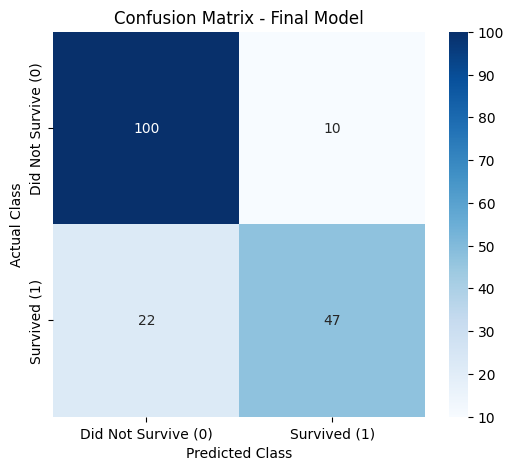

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Did Not Survive (0)', 'Survived (1)'],
    yticklabels=['Did Not Survive (0)', 'Survived (1)']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix - Final Model')
plt.show()

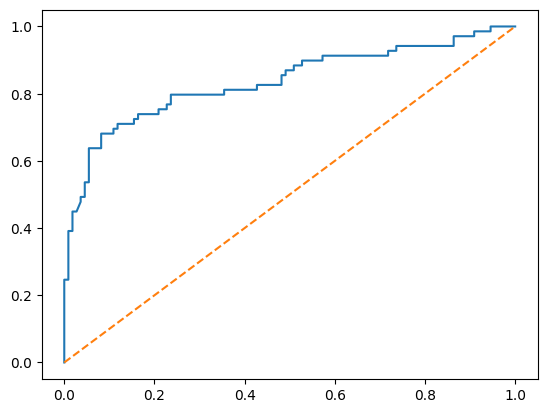

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_final
)

plt.plot(
    fpr,
    tpr,
    label=f'Final Model (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)



## **What does the ROC curve tell you?**
The ROC curve shows the relationship between the true positive
rate and false positive rate at different classification thresholds.
A higher ROC-AUC indicates better discrimination between the
survived and not-survived classes

In [ ]:
import pickle

# Save the actual selected final model
best_model = final_model

with open('titanic_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

print("Best Model:", best_name)
print("Model saved successfully!")

Best Model: Tuned Random Forest
Model saved successfully!


In [ ]:
new_passenger = pd.DataFrame({
    'Pclass': [3],
    'Sex': ['male'],
    'Age': [25],
    'Fare': [7.25],
    'Embarked': ['S']
})

In [ ]:
import pickle

with open('titanic_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
loaded_model.predict(new_passenger)

array([0])